## Issues causing initialization ::
 #### Case 1 zero initialization :

 All weights will become zero and remain unchanged for the relu and tanh . And in sigmoid, the weights for each node will be same loosing non linearlity 

 #### Case 2 Non - zero constant :

 All weights for a node will be same , ie all output weights from a node will act as one with same value . This also make model like a perceptron with inability to capture non - linearlity 

 #### Case 3 very small random numbers  : 
 
 This cause the activations value will be very very close to zero . This cause the gradients to be very small . Causing the vanishing gradient problem in tanh and sigmoid  . 
 
 And in deep NN the convergence will be very slow for relu ( as in relu activations doesnot become zero mostly)


 #### Case 4 very large random numbers :



In [39]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [40]:
df = pd.read_csv('../../data/ushape.csv')

In [41]:
df

,X,Y,class
0,0.031595,0.986988,0.0
1,2.115098,-0.046244,1.0
2,0.882490,-0.075756,0.0
3,-0.055144,-0.037332,1.0
4,0.829545,-0.539321,1.0
...,...,...,...
95,1.699453,0.587720,1.0
96,0.218623,-0.652521,1.0
97,0.952914,-0.419766,1.0
98,-1.318500,0.423112,0.0


In [42]:
df.isnull

<bound method DataFrame.isnull of            X         Y  class
0   0.031595  0.986988    0.0
1   2.115098 -0.046244    1.0
2   0.882490 -0.075756    0.0
3  -0.055144 -0.037332    1.0
4   0.829545 -0.539321    1.0
..       ...       ...    ...
95  1.699453  0.587720    1.0
96  0.218623 -0.652521    1.0
97  0.952914 -0.419766    1.0
98 -1.318500  0.423112    0.0
99 -1.296818  0.184147    0.0

[100 rows x 3 columns]>

In [43]:
df.head()

,X,Y,class
0,0.031595,0.986988,0.0
1,2.115098,-0.046244,1.0
2,0.882490,-0.075756,0.0
3,-0.055144,-0.037332,1.0
4,0.829545,-0.539321,1.0


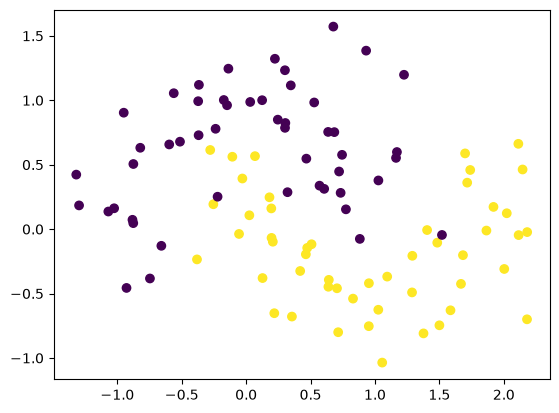

In [44]:
plt.scatter(df['X'],df['Y'],c=df['class'])

In [45]:
X = df.iloc[:,0:2].values
y = df.iloc[:,-1].values

In [46]:
type(y.astype('int'))

numpy.ndarray

In [47]:
import tensorflow
from tensorflow import keras
from keras import Sequential
from keras.layers import Dense

In [48]:
model = Sequential()

model.add(Dense(10,activation='sigmoid',input_dim=2))
model.add(Dense(1,activation='sigmoid'))

model.summary()

/home/foolmann/miniconda3/envs/ml312/lib/python3.12/site-packages/keras/src/layers/core/dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                 │ (None, 10)             │            30 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            11 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 41 (164.00 B)

 Trainable params: 41 (164.00 B)

 Non-trainable params: 0 (0.00 B)

In [49]:
# Set parameters to 0
model.get_weights()

[array([[ 0.01849288, -0.3897115 , -0.06448853, -0.09148633,  0.25243014,
          0.58395   ,  0.27519953, -0.03957385,  0.1324318 , -0.17445272],
        [ 0.5763145 ,  0.5531263 ,  0.06108832,  0.49509162, -0.21450013,
          0.00526428, -0.58913016, -0.32147205,  0.31326038, -0.08722258]],
       dtype=float32),
 array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0.], dtype=float32),
 array([[ 0.5883346 ],
        [-0.24853593],
        [ 0.68061775],
        [ 0.40548962],
        [-0.03271317],
        [-0.33264798],
        [-0.01491624],
        [-0.39889687],
        [ 0.12200212],
        [-0.6824279 ]], dtype=float32),
 array([0.], dtype=float32)]

In [50]:
initial_weights = model.get_weights()

Overwriting the default weights f4om the keras to zeros 

In [51]:
initial_weights[0] = np.zeros(model.get_weights()[0].shape)
initial_weights[1] = np.zeros(model.get_weights()[1].shape)
initial_weights[2] = np.zeros(model.get_weights()[2].shape)
initial_weights[3] = np.zeros(model.get_weights()[3].shape)

In [52]:
model.set_weights(initial_weights)

In [53]:
model.get_weights()

[array([[0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]], dtype=float32),
 array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0.], dtype=float32),
 array([[0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.]], dtype=float32),
 array([0.], dtype=float32)]

In [54]:
model.compile(loss='binary_crossentropy',optimizer='adam',metrics=['accuracy'])

In [55]:
history = model.fit(X,y,epochs=100,validation_split=0.2)

Epoch 1/100


I0000 00:00:1795365566.857888    7081 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_275622__.8


1/3 ━━━━━━━━━━━━━━━━━━━━ 1s 998ms/step - accuracy: 0.5312 - loss: 0.6931

I0000 00:00:1795365567.246780    7082 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_275622__.8


3/3 ━━━━━━━━━━━━━━━━━━━━ 2s 316ms/step - accuracy: 0.5000 - loss: 0.6932 - val_accuracy: 0.5000 - val_loss: 0.6931
Epoch 2/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - accuracy: 0.5000 - loss: 0.6932 - val_accuracy: 0.5000 - val_loss: 0.6931
Epoch 3/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - accuracy: 0.5000 - loss: 0.6932 - val_accuracy: 0.5000 - val_loss: 0.6931
Epoch 4/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.5000 - loss: 0.6931 - val_accuracy: 0.5000 - val_loss: 0.6931
Epoch 5/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.5000 - loss: 0.6931 - val_accuracy: 0.5000 - val_loss: 0.6931
Epoch 6/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.3750 - loss: 0.6933 - val_accuracy: 0.5000 - val_loss: 0.6932
Epoch 7/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - accuracy: 0.5000 - loss: 0.6932 - val_accuracy: 0.5000 - val_loss: 0.6932
Epoch 8/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - accuracy: 0.5000 - loss: 0.6932 - val_accuracy: 0.5000 - val_loss: 0.6932
Epo

In [56]:
model.get_weights()

[array([[ 0.41577727,  0.41577727,  0.41577727,  0.41577727,  0.41577727,
          0.41577727,  0.41577727,  0.41577727,  0.41577727,  0.41577727],
        [-0.4457721 , -0.4457721 , -0.4457721 , -0.4457721 , -0.4457721 ,
         -0.4457721 , -0.4457721 , -0.4457721 , -0.4457721 , -0.4457721 ]],
       dtype=float32),
 array([-0.13188559, -0.13188559, -0.13188559, -0.13188559, -0.13188559,
        -0.13188559, -0.13188559, -0.13188559, -0.13188559, -0.13188559],
       dtype=float32),
 array([[0.04395835],
        [0.04395835],
        [0.04395835],
        [0.04395835],
        [0.04395835],
        [0.04395835],
        [0.04395835],
        [0.04395835],
        [0.04395835],
        [0.04395835]], dtype=float32),
 array([-0.03978533], dtype=float32)]

We can see that our weights from one inputs are same and for other sets of input to the weights are same  . This is due to zero initialization . All nodes in a layer will act like a single node this will act like a perceptron or linear model . So , non linearity will not be captured . 

In [57]:
print(X.dtype)
print(y.dtype)
print(X.shape)
print(y.shape)

float64
float64
(100, 2)
(100,)


In [58]:
print(X.dtypes)

AttributeError: 'numpy.ndarray' object has no attribute 'dtypes'

In [ ]:
print("X:", X.shape, X.dtype)
print("y:", y.shape, y.dtype)
print("Predictions:", model.predict(X)[:10])

X: (100, 2) float64
y: (100,) float64
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 78ms/step
Predictions: [[0.51451725]
 [0.5194421 ]
 [0.5176072 ]
 [0.51608723]
 [0.5182946 ]
 [0.5182799 ]
 [0.51643157]
 [0.5188336 ]
 [0.51540905]
 [0.51816815]]


<Axes: >

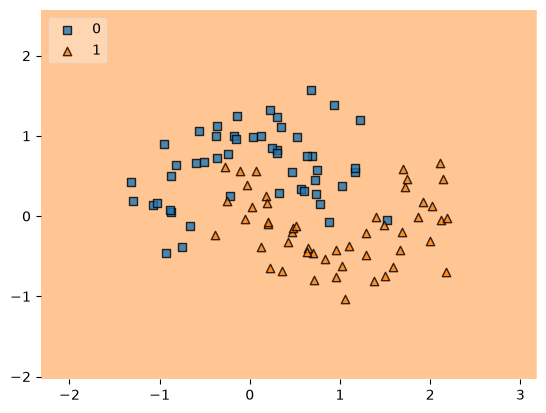

In [ ]:
import numpy as np
from mlxtend.plotting import plot_decision_regions

class KerasClassifier:
    def __init__(self, model):
        self.model = model

    def predict(self, X):
        predictions = self.model.predict(X, verbose=0)
        return (predictions.ravel() >= 0.5).astype(int)


# Convert labels to integers
y = y.astype(int)

# Wrap the model
clf = KerasClassifier(model)

# Plot decision regions
plot_decision_regions(X, y, clf=clf, legend=2)

In [ ]:
# from mlxtend.plotting import plot_decision_regions
# plot_decision_regions(X,y.astype('int'), clf=model, legend=2)

In [ ]:
X.dtype

dtype('float64')